# Del Perceptrón al MLP: construyendo una red neuronal desde cero

Una red neuronal es, en esencia, **una composición de funciones lineales y no lineales**
cuyos parámetros se ajustan por descenso de gradiente.

- El **perceptrón** es la unidad más simple: `y = f(w·x + b)`.
- Un **MLP** (Multi-Layer Perceptron) es la composición de varias de estas unidades
  en **capas ocultas**: `y = f_L( ... f_2(W_2 f_1(W_1 x + b_1) + b_2) ... )`.

En este notebook:
1. Construimos el perceptrón desde cero (NumPy).
2. Vemos su limitación: **solo separa datos linealmente separables**.
3. Construimos un MLP desde cero con **forward pass + backpropagation**.
4. Lo probamos sobre dígitos escritos a mano (sklearn `digits`, 8×8, 1797 muestras).
5. Confirmamos el mismo resultado con `sklearn.MLPClassifier` y `torch.nn.Sequential`.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pylab as pl
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams['figure.figsize'] = (5, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True

## Parte 1. El perceptrón: la neurona artificial

Recordemos el modelo:

$$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$

$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

**Regla de aprendizaje (perceptrón clásico, Rosenblatt 1958):**

$$w_i \leftarrow w_i + \eta (y - \hat{y}_{bin}) \, x_i, \qquad b \leftarrow b + \eta (y - \hat{y}_{bin})$$

donde $\hat{y}_{bin} = \mathbb{1}[\sigma(z) \ge 0.5]$ y $\eta$ es la tasa de aprendizaje.

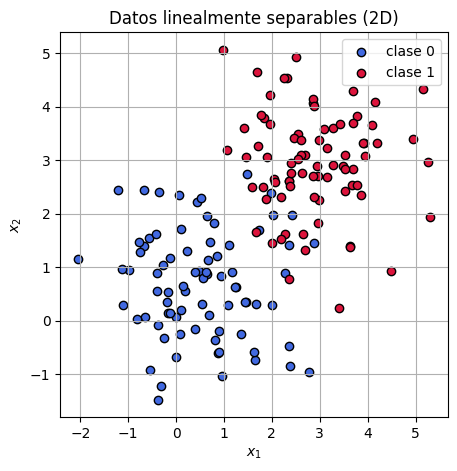

X_2d: (160, 2), y_2d: (160,)


In [11]:
np.random.seed(0)
n = 80
class_0 = np.random.randn(n,2) + np.array([0.5,0.5])   # Objetos clase 0, centrados en (0.5,0.5)
class_1 = np.random.randn(n,2) + np.array([3,3]) # Objetos clase 1, centrados en (3,3)

X_2d = np.vstack([class_0, class_1])
y_2d = np.array([0]*n+[1]*n)


#plt.scatter(X_2d[:,0], X_2d[:,1], c=y_2d, cmap='bwr')
#print(X_2d[0], y_2d[0])

# Mezclamos
idx = np.random.permutation(2*n)
X_2d, y_2d = X_2d[idx], y_2d[idx]

# Visualización
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_2d[y_2d==0, 0], X_2d[y_2d==0, 1], c='royalblue', label='clase 0', edgecolor='k')
ax.scatter(X_2d[y_2d==1, 0], X_2d[y_2d==1, 1], c='crimson',   label='clase 1', edgecolor='k')
ax.set_title('Datos linealmente separables (2D)')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.legend()
plt.show()

print(f"X_2d: {X_2d.shape}, y_2d: {y_2d.shape}")

In [35]:
class Perceptron:
  def __init__(self, n_features, lr=0.1):
    self.w = np.zeros(n_features)
    self.b = 0
    self.lr = lr

  def _sigmoid(self,z):
    return 1/(1+np.exp(-z))

  def forward(self, X):
    z = X @ self.w + self.b
    return self._sigmoid(z)

  def predict(self, X):
    return (self.forward(X) >= 0.5).astype(int)

  def fit(self, X, y, n_epochs=10):
    history = {'loss': [], 'acc': []}
    for epoch in range(n_epochs):
      y_pred = self.predict(X)
      error = y - y_pred
      self.w += self.lr * error.T@X
      self.b += self.lr * np.sum(error)

      probs = self.forward(X)
      loss = np.mean((y - probs)**2)
      acc = np.mean(y == self.predict(X))
      history['loss'].append(loss)
      history['acc'].append(acc)
    return history

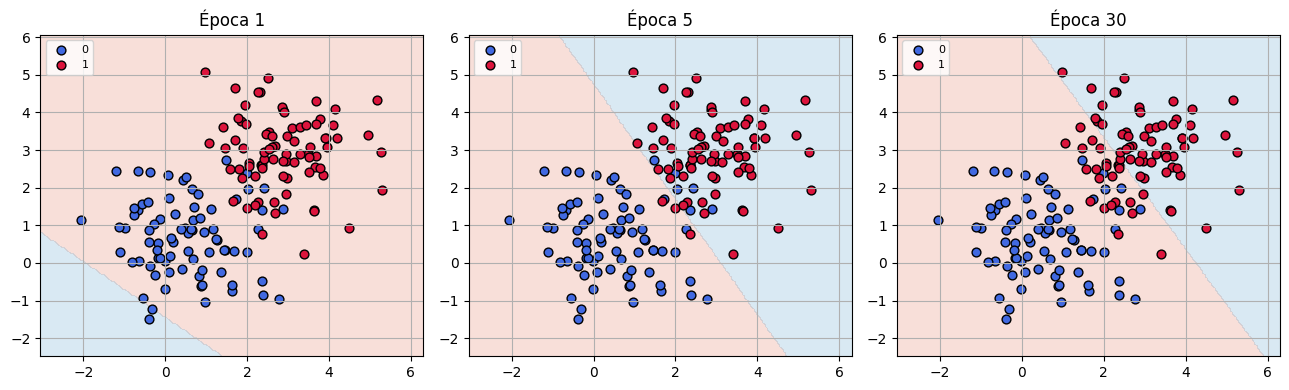

Pesos finales: w = [4.04749626 2.72539271], b = -17.199999999999996
Accuracy final: 0.8562


In [36]:
def plot_boundary(ax, model, X, y, title=''):
    """Pinta la frontera de decisión de un clasificador binario 2D."""
    x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
    y_min, y_max = X[:,1].min()-1, X[:,1].max()+1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='RdBu', levels=[-0.5, 0.5, 1.5])
    ax.scatter(X[y==0, 0], X[y==0, 1], c='royalblue', edgecolor='k', s=40, label='0')
    ax.scatter(X[y==1, 0], X[y==1, 1], c='crimson',   edgecolor='k', s=40, label='1')
    ax.set_title(title)
    ax.legend(loc='upper left', fontsize=8)

# Entrenamos
perc = Perceptron(n_features=2, lr=0.1)
hist = perc.fit(X_2d, y_2d, n_epochs=30)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, ep in zip(axes, [0, 4, 29]):
    # Entrenamos solo hasta esa época para mostrar la evolución
    p = Perceptron(n_features=2, lr=0.1)
    p.fit(X_2d, y_2d, n_epochs=ep+1)
    plot_boundary(ax, p, X_2d, y_2d, title=f'Época {ep+1}')
plt.tight_layout(); plt.show()

print(f"Pesos finales: w = {perc.w}, b = {perc.b}")
print(f"Accuracy final: {hist['acc'][-1]:.4f}")

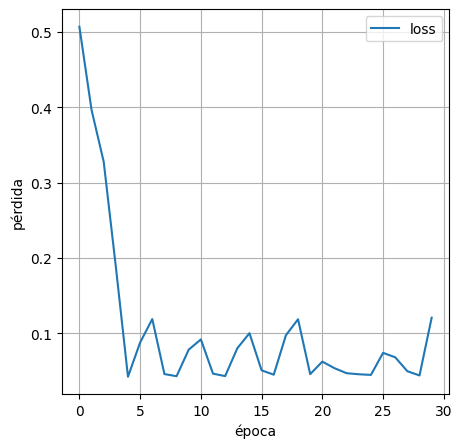

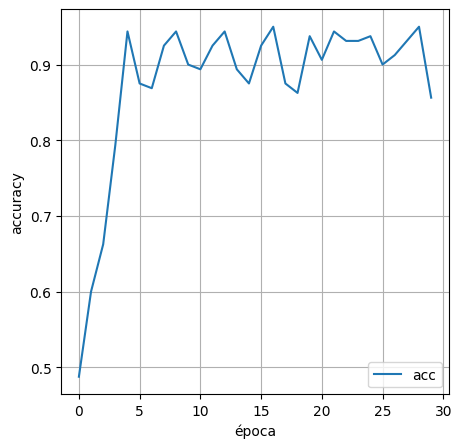

In [39]:
plt.plot(range(30),hist['loss'], label='loss')
plt.xlabel('época')
plt.ylabel('pérdida')
plt.legend()
plt.show()

plt.plot(range(30), hist['acc'], label='acc')
plt.xlabel('época')
plt.ylabel('accuracy')
plt.legend()
plt.show()